In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

In [3]:
df_train = pd.read_csv('./train.csv', header=None)

In [23]:
df_train.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Columns: 5000 entries, 0 to 4999
dtypes: float64(5000)
memory usage: 38.1 MB


In [5]:
first_series = df_train.iloc[0]

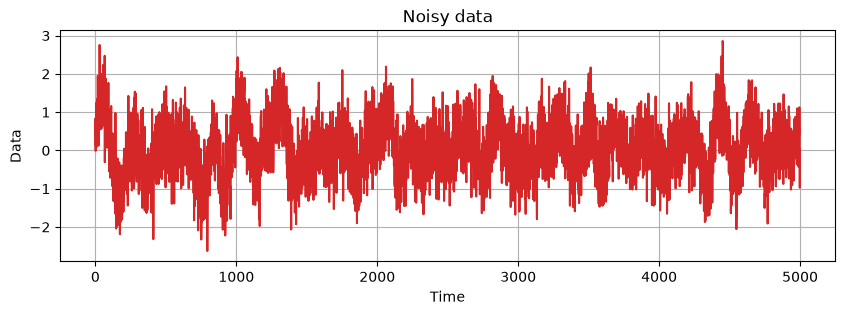

In [ ]:
# пример временного ряда из обучающей выборки с шумом
fig, ax = plt.subplots(1, 1, figsize=(10, 3))
ax.plot(np.arange(len(first_series)), first_series, color='tab:red')
ax.set_xlabel("Time")
ax.set_ylabel("Data")
plt.title("Noisy data");
plt.grid()

In [7]:
df_train_etalon = pd.read_csv('./etalon_for_train.csv', header=None)

In [25]:
df_train_etalon.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Columns: 5000 entries, 0 to 4999
dtypes: float64(5000)
memory usage: 38.1 MB


In [26]:
first_series_etalon = df_train_etalon.iloc[0]

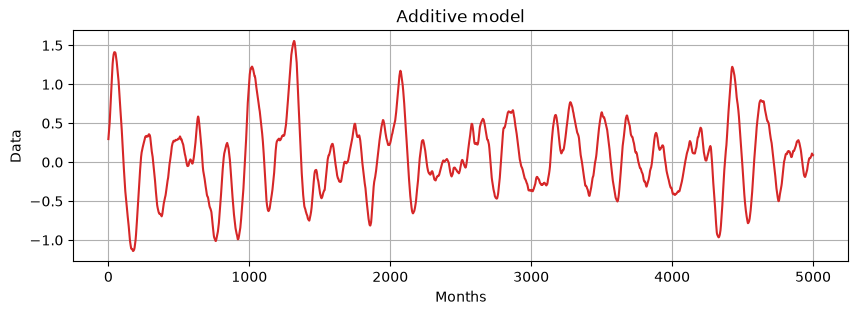

In [28]:
# пример временного ряда из обучающей выборки с шумом
fig, ax = plt.subplots(1, 1, figsize=(10, 3))
ax.plot(np.arange(len(first_series_etalon)), first_series_etalon, color='tab:red')
ax.set_xlabel("Months")
ax.set_ylabel("Data")
plt.title("Additive model");
plt.grid()

Модель создана. Обучение на устройстве: cuda
Начало обучения

Эпоха [5/60], Loss (MSE): 1.001
Эпоха [10/60], Loss (MSE): 1.003
Эпоха [15/60], Loss (MSE): 0.897
Эпоха [20/60], Loss (MSE): 0.679
Эпоха [25/60], Loss (MSE): 0.561
Эпоха [30/60], Loss (MSE): 0.479
Эпоха [35/60], Loss (MSE): 0.411
Эпоха [40/60], Loss (MSE): 0.367
Эпоха [45/60], Loss (MSE): 0.328
Эпоха [50/60], Loss (MSE): 0.290
Эпоха [55/60], Loss (MSE): 0.252
Эпоха [60/60], Loss (MSE): 0.225


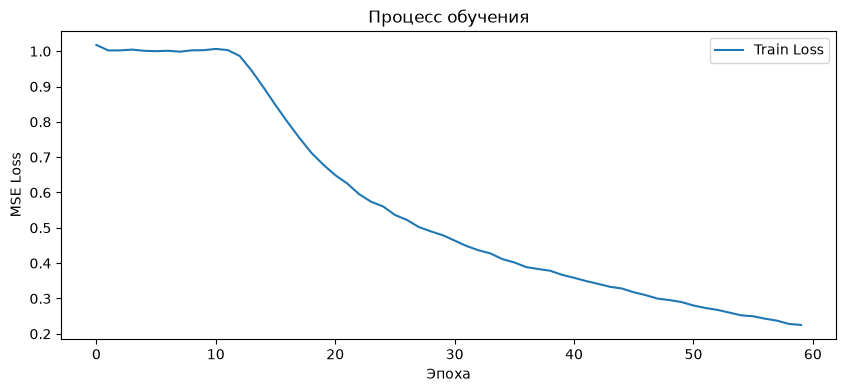

In [29]:
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
import math

path_train = './train.csv'
path_etalon_train = './etalon_for_train.csv'
path_test = './test.csv'
path_etalon_test = './etalon_for_test.csv'

df_train = pd.read_csv(path_train, header=None)
df_etalon_train = pd.read_csv(path_etalon_train, header=None)
df_test = pd.read_csv(path_test, header=None)
df_etalon_test = pd.read_csv(path_etalon_test, header=None)

history_len = 4000  # 200 секунд
forecast_len = 1000 # 50 секунд
dt = 0.05

# .values преобразует DataFrame в массив numpy
X_train = df_train.iloc[:, :history_len].values # обучающая выборка из зашумленных данных
Y_train = df_etalon_train.iloc[:, history_len:].values # истинные значения обучающей выборки из эталонных данных

X_test = df_test.iloc[:, :history_len].values # тестовая выборка из зашумленных данных
Y_test = df_etalon_test.iloc[:, history_len:].values # истинные значения тестовой выборки из эталонных данных

# нормализация данных (StandardScaler)
scaler_X = StandardScaler()
scaler_Y = StandardScaler()

# вычисление среднего и std и приминение
X_train_scaled = scaler_X.fit_transform(X_train)
Y_train_scaled = scaler_Y.fit_transform(Y_train)

# применение нормализации на основе train
X_test_scaled = scaler_X.transform(X_test)
Y_test_scaled = scaler_Y.transform(Y_test)

# преобразование массивов numpy в тензоры PyTorch и добавление размерности признака 
# .unsqueeze(-1) добавляет последнюю размерность (1000, 4000) -> (1000, 4000, 1)
# трансформер ожидает на входе (batch, sequence_length, features)
X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32).unsqueeze(-1)
Y_train_tensor = torch.tensor(Y_train_scaled, dtype=torch.float32)

X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32).unsqueeze(-1)
Y_test_tensor = torch.tensor(Y_test_scaled, dtype=torch.float32)

# DataLoader для подачи данных в модель батчами
batch_size = 32
train_dataset = TensorDataset(X_train_tensor, Y_train_tensor)
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)

# input_dim=1     -> один признак (амплитуда сигнала)
# d_model=64      -> внутренняя размерность модели, каждый вход преобразуется в вектор из 64 чисел 
# nhead=4         -> 4 головы внимания
# num_layers=2    -> 2 слоя трансформер-энкодера 
# output_dim=1000 -> длина прогноза 
# max_len=4000	  -> максимальная длина входной последовательности
class TimeSeriesTransformer(nn.Module):
    def __init__(self, input_dim=1, d_model=64, nhead=4, num_layers=2, output_dim=1000, max_len=4000):
        super(TimeSeriesTransformer, self).__init__()
        
        # проекция входа (одного числа - амплитуды сигнала) в размерность d_model
        self.input_proj = nn.Linear(input_dim, d_model)
        
        # позиционное кодирование
        # трансформер обрабатывает все 4000 точек одновременно и не знает их порядок, а он важен
        # к каждому шагу добавляется вектор, который зависит от его номера
        # изначально все векторы случайны , но при обучении настраиваются
        self.pos_encoder = nn.Parameter(torch.randn(1, max_len, d_model))
        
        # слои трансформера
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model, 
            nhead=nhead, 
            dim_feedforward=128, 
            dropout=0.1,
            batch_first=True
        )
        self.transformer_encoder = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)
        
        # выходной слой: получение вектора прогноза
        self.fc = nn.Linear(d_model, output_dim)

    def forward(self, x):
        # x: (batch, 4000, 1)
        x = self.input_proj(x) # -> (batch, 4000, d_model)
        x = x + self.pos_encoder # добавление позиции
        
        # проход трансформера
        x = self.transformer_encoder(x) # -> (batch, 4000, d_model)
        
        # усреднение по всей истории
        x = x.mean(dim=1) # -> (batch, d_model)
        
        # прогноз
        x = self.fc(x) # -> (batch, 1000)
        return x


device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = TimeSeriesTransformer(output_dim=forecast_len).to(device)

criterion = nn.MSELoss() # среднеквадратичная ошибка
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

print(f"Модель создана. Обучение на устройстве: {device}")


epochs = 60
train_losses = []

print("Начало обучения\n")
for epoch in range(epochs):
    model.train()
    epoch_loss = 0
    for batch_X, batch_Y in train_loader:
        batch_X, batch_Y = batch_X.to(device), batch_Y.to(device)
        
        optimizer.zero_grad()
        predictions = model(batch_X)
        loss = criterion(predictions, batch_Y)
        loss.backward()
        optimizer.step()
        
        epoch_loss += loss.item()
    
    avg_loss = epoch_loss / len(train_loader)
    train_losses.append(avg_loss)
    
    if (epoch+1) % 5 == 0:
        print(f"Эпоха [{epoch+1}/{epochs}], Loss (MSE): {avg_loss:.3f}")


plt.figure(figsize=(10, 4))
plt.plot(train_losses, label='Train Loss')
plt.title('Процесс обучения')
plt.xlabel('Эпоха')
plt.ylabel('MSE Loss')
plt.legend()
plt.show()

Тестирование


Средняя ошибка: 0.0074
Средний RMS: 0.6859


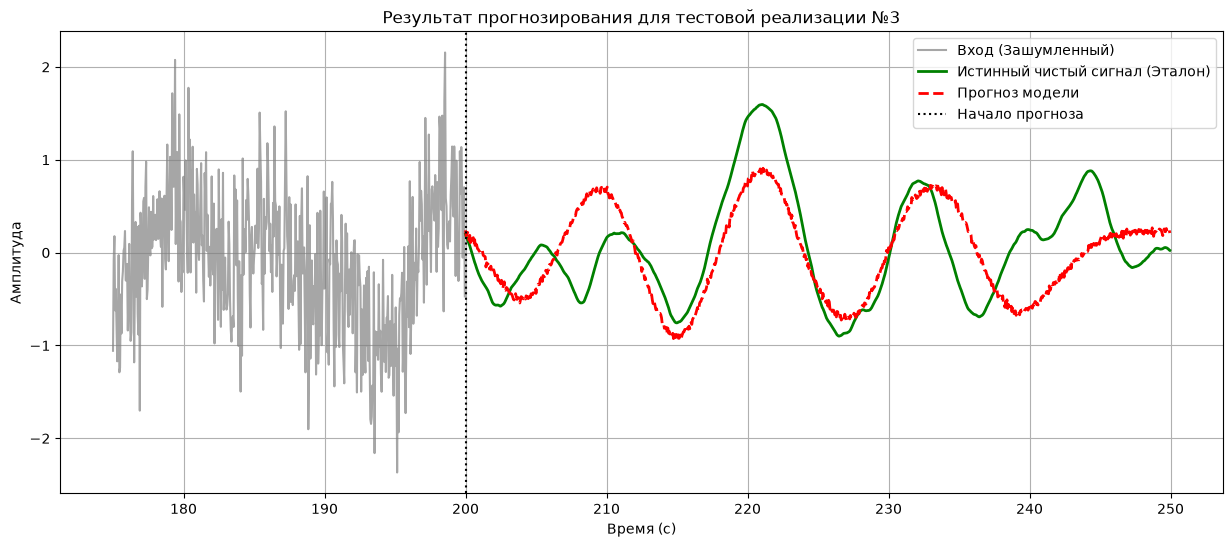

In [ ]:
print("Тестирование\n")
model.eval()
with torch.no_grad(): # отключение вычисления градиентов
    X_test_tensor = X_test_tensor.to(device)
    predictions_scaled = model(X_test_tensor).cpu().numpy()

# обратная нормализация (возврат к исходным амплитудам)
predictions = scaler_Y.inverse_transform(predictions_scaled)

# расчет метрик из задачи
# средняя ошибка 
error = predictions - Y_test
mean_error = np.mean(error, axis=0)

# среднеквадратические погрешности
L = error.shape[0] 
rms = np.sqrt(np.sum((error - mean_error)**2, axis=0) / (L - 1))

print(f"\nСредняя ошибка: {np.mean(mean_error):.4f}")
print(f"Средний RMS: {np.mean(rms):.4f}")


idx = 3
time_axis_forecast = np.arange(history_len, history_len + forecast_len) * dt

plt.figure(figsize=(15, 6))

plt.plot(np.arange(history_len-500, history_len) * dt, X_test[idx, -500:], 
         label='Вход (Зашумленный)', color='gray', alpha=0.7)

plt.plot(time_axis_forecast, Y_test[idx], 
         label='Истинный чистый сигнал (Эталон)', color='green', linewidth=2)

plt.plot(time_axis_forecast, predictions[idx], 
         label='Прогноз модели', color='red', linestyle='--', linewidth=2)

plt.axvline(x=history_len*dt, color='black', linestyle=':', label='Начало прогноза')
plt.title(f'Результат прогнозирования для тестовой реализации №{idx}')
plt.xlabel('Время (с)')
plt.ylabel('Амплитуда')
plt.legend()
plt.grid(True)
plt.show()